https://huggingface.co/datasets/lmsys/lmsys-chat-1m

In [ ]:
!pip install datasets pandas
!pip install ipykernel
!pip install -U brotli brotlicffi httpx huggingface_hub datasets

In [ ]:
%pip install matplotlib
%pip install seaborn
%pip install datasets

In [ ]:
%pip install plotly
%pip install plotly.express

In [15]:
%pip install --upgrade nbformat

  Using cached nbformat-5.11.1-py3-none-any.whl.metadata (3.7 kB)
  Using cached fastjsonschema-2.22.3-py3-none-any.whl.metadata (2.1 kB)
  Using cached jsonschema-4.26.0-py3-none-any.whl.metadata (7.6 kB)
  Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl.metadata (2.9 kB)
  Using cached referencing-0.37.0-py3-none-any.whl.metadata (2.8 kB)
Using cached nbformat-5.11.1-py3-none-any.whl (79 kB)
Using cached fastjsonschema-2.22.3-py3-none-any.whl (28 kB)
Using cached jsonschema-4.26.0-py3-none-any.whl (90 kB)
Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl (18 kB)
Using cached referencing-0.37.0-py3-none-any.whl (26 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 341.4/341.4 kB 2.0 MB/s eta 0:00:00a 0:00:01m

[notice] A new release of pip is available: 24.1.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import plotly.express as px

In [2]:
from datasets import load_dataset
ds = load_dataset("lmsys/lmsys-chat-1m", split="train", streaming=True)
row = next(iter(ds))
print(row["conversation"][0]["content"][:220])

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


how can identity protection services help protect me against identity theft


# preparing the dataset

In [ ]:
# loading the first 10,000 rows of ds to a pandas df
# help take from ChatGPT to convert a ds to df.
lmsys_chat_df = pd.DataFrame(list(ds.take(80000)))

In [4]:
display(lmsys_chat_df.head())
round(lmsys_chat_df.describe(), 2)

,conversation_id,model,conversation,turn,language,openai_moderation,redacted
0,33f01939a744455c869cb234afca47f1,wizardlm-13b,[{'content': 'how can identity protection serv...,1,English,"[{'categories': {'harassment': False, 'harassm...",False
1,1e230e55efea4edab95db9cb87f6a9cb,vicuna-13b,[{'content': 'Beside OFAC's selective sanction...,6,English,"[{'categories': {'harassment': False, 'harassm...",False
2,0f623736051f4a48a506fd5933563cfd,vicuna-13b,[{'content': 'You are the text completion mode...,1,English,"[{'categories': {'harassment': False, 'harassm...",False
3,e5c923a7fa3f4893beb432b4a06ef222,palm-2,[{'content': 'The sum of the perimeters of thr...,2,English,"[{'categories': {'harassment': False, 'harassm...",False
4,8ad66650dced4b728de1d14bb04657c1,vicuna-13b,[{'content': 'What is the type of the variable...,1,English,"[{'categories': {'harassment': False, 'harassm...",False


,turn
count,80000.00
mean,2.03
std,2.74
min,1.00
25%,1.00
50%,1.00
75%,2.00
max,106.00


In [25]:
# splitting df into toxic ("flagged") and nontoxic (not flagged")
records = []

for _, row in lmsys_chat_df.iterrows():
    messages = row["conversation"]
    moderation = row["openai_moderation"]

    assert len(messages) == len(moderation), "Message/moderation lengths differ"

    for i, (message, labels) in enumerate(zip(messages, moderation)):
        records.append({
            "conversation_id": row["conversation_id"],
            "message_index": i,
            "role": message["role"],
            "content": message["content"],
            "flagged": labels["flagged"],
            "flagged_categories": [
                category
                for category, flagged in labels["categories"].items()
                if flagged
            ]
        })
message_split_df = pd.DataFrame(records)

In [ ]:
# combining messages_split_df with lmsys_chat_df
messages_df = pd.concat(message_split_df, lmsys_chat_df

###
My prepared dataset has two dataframes that I will use in this analysis:
1. lmsys_chat_df where each row represents one conversation - including user and assistant messages, flag status, and all flagged categories. this can be used to analyze number of turns and conversation counts.
2. messages_df where for each conversation_id, we have one row with the users message, and one row with the assistant's message. For a conversation with 6 turns, we will have 6 rows for the user for that conversation id, and 6 rows with the assistants responses.
##

# understanding the dataset

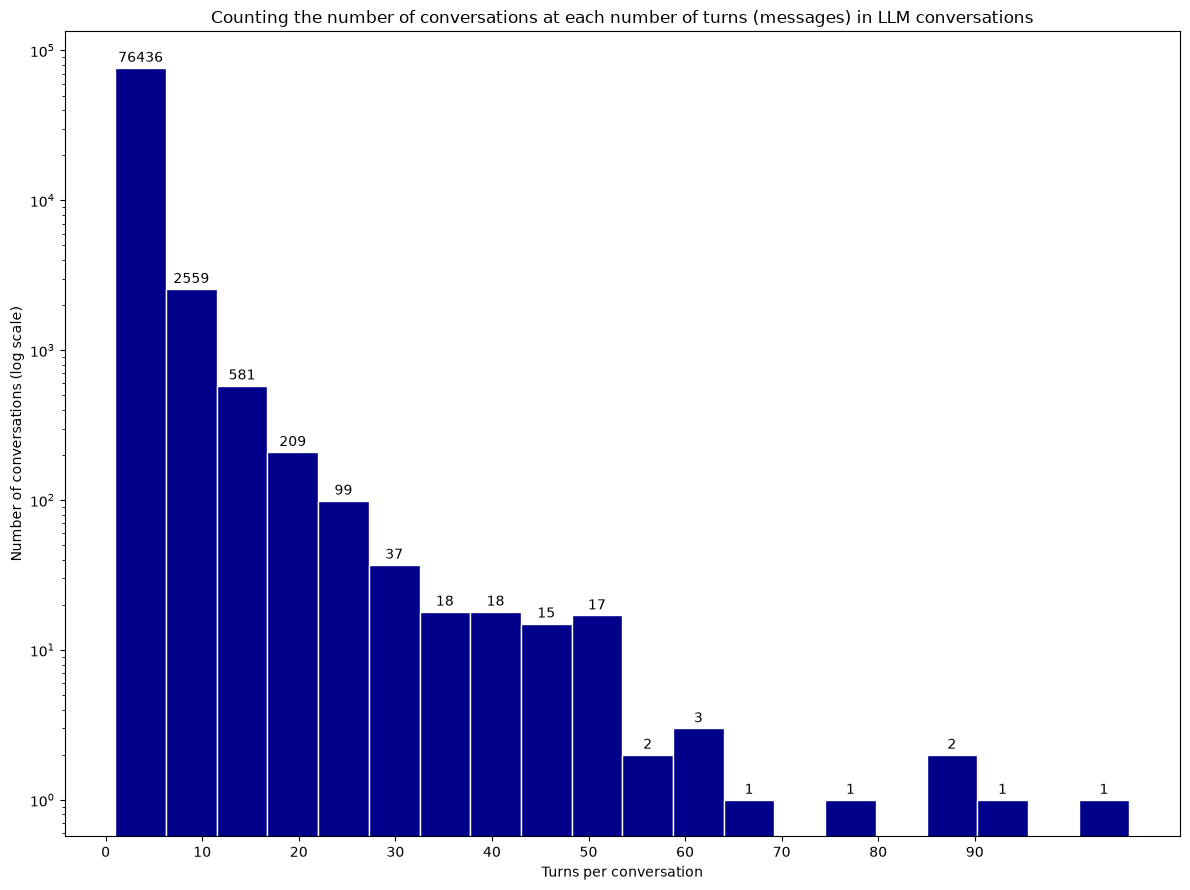

In [ ]:
# visualizing the number of turns in each conversation to understand the number of messages exchanged between the user and assistant
plt.figure(figsize=(12, 9))
counts, bins, patches = plt.hist(lmsys_chat_df["turn"], bins=20, log=True, color="darkblue", edgecolor="white", label=lmsys_chat_df["turn"])
plt.bar_label(patches, fmt="%.0f", padding=2)
plt.xlabel("Turns per conversation")
plt.ylabel("Number of conversations (log scale)")
plt.title("Counting the number of conversations at each number of turns (messages) in LLM conversations")
plt.xticks(np.arange(0, 100, 10))
plt.tight_layout()
plt.show()

print()

In [ ]:
# conversation lengths (number of turns) for flagged (toxic) and unflagged (non-toxic) conversations


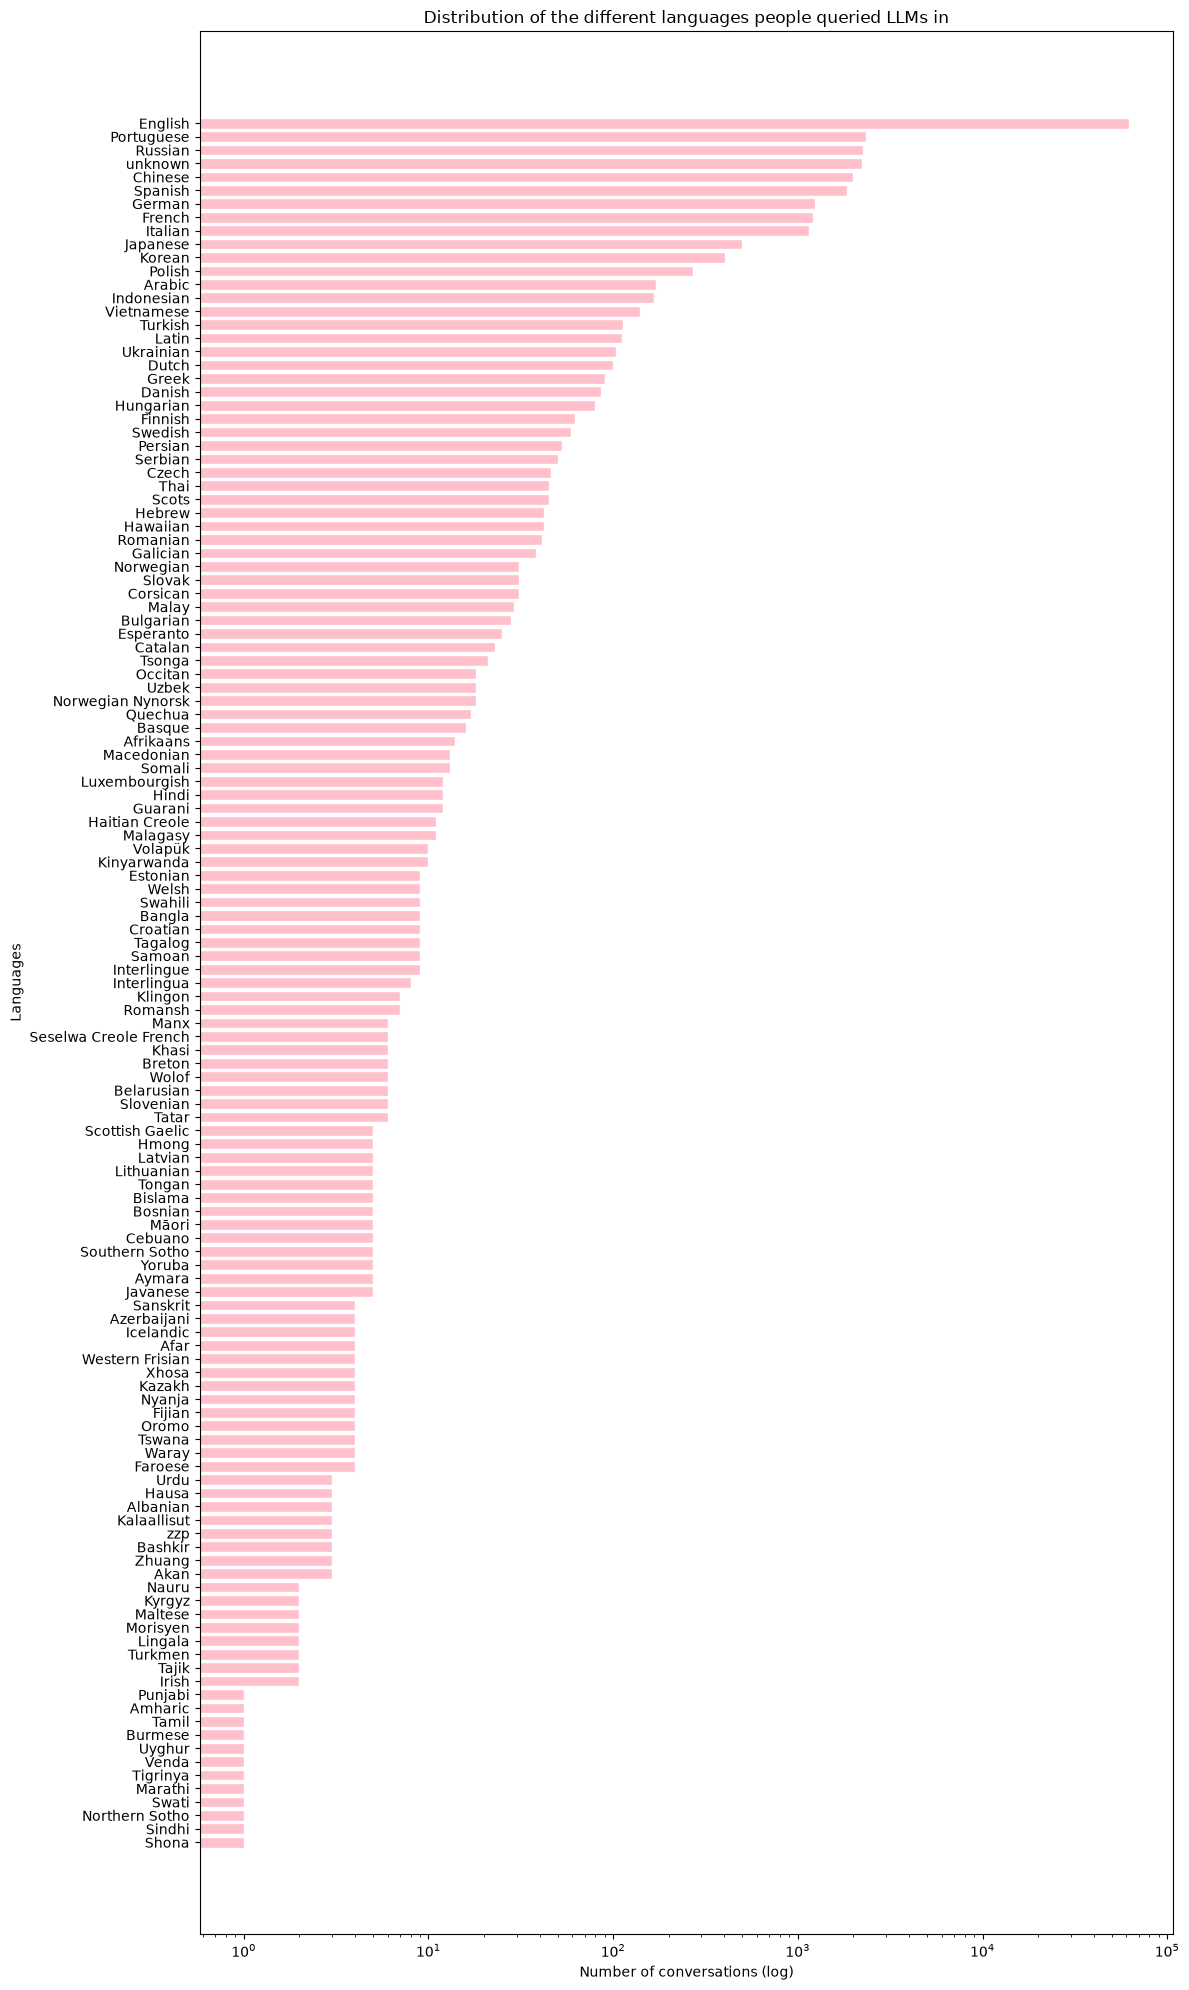

In [6]:
# languages that people chat in
language_counts = lmsys_chat_df["language"].value_counts()

plt.figure(figsize=(12,20))
plt.barh(language_counts.index, language_counts.values, log=True, color="pink", edgecolor="white")
plt.gca().invert_yaxis()
plt.xlabel("Number of conversations (log)")
plt.ylabel("Languages")
plt.title("Distribution of the different languages people queried LLMs in")
plt.tight_layout()
plt.show()

print()

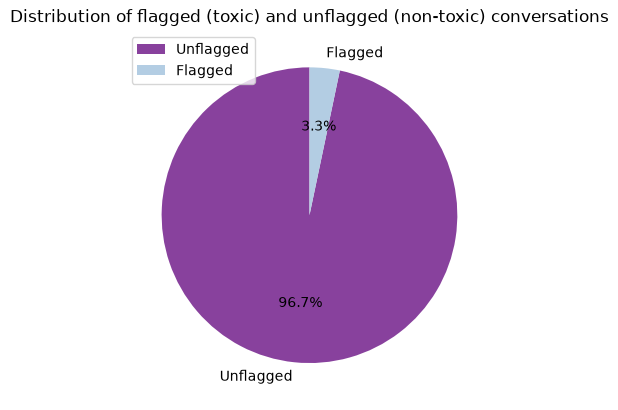

In [8]:
# pie chart of flagged and unflagged conversations
messages_df["flagged"].value_counts().rename({True:"Flagged", False:"Unflagged"}).plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    colors=["#88419d", "#b3cde3"],
    ylabel="",
    title="Distribution of flagged (toxic) and unflagged (non-toxic) conversations")
plt.legend(loc="upper left")
plt.show()

In [ ]:
# how many messages are flagged by role (user, assistant)
message_flag_status_df = pd.DataFrame(messages_df.groupby(["role", "flagged"])["flagged_categories"].count())
message_flag_status_df
# visualizing as pie charts
fig, ax = plt.subplots()

flagged_categories
role      flagged                    
assistant False                156515
          True                   5526
user      False                156898
          True                   5143

In [ ]:
# lengths of flagged and unflagged conversations

In [ ]:
# moderation categories and how often each category is flagged
# counting the number of times each moderation category occurs
category_counts = (messages_df["flagged_categories"]
                   .explode()
                   .value_counts()
                   .rename_axis("category") # renames the current index as category
                   .reset_index(name="count") # moving the index column into the regular columns
)
# visualizing category_counts
fig = px.treemap(
    category_counts,
    path=["category"],
    values="count",
    title="Frequency of moderation categories flagged across toxic conversations"
)
fig.update_traces(
    textinfo="label+value",
    hovertemplate="<b>%{label}</b><br>Flagged messages: %{value}<extra></extra>"
)

fig.show()
print("note that a single conversation can have multiple categories, so this does not total to the total number of conversations.")

In [ ]:
# flag rates and moderation categories for users vs assistants


,conversation_id,message_index,role,content,flagged,flagged_categories
0,33f01939a744455c869cb234afca47f1,0,user,how can identity protection services help prot...,False,[]
1,33f01939a744455c869cb234afca47f1,1,assistant,Identity protection services can help protect ...,False,[]
2,1e230e55efea4edab95db9cb87f6a9cb,0,user,Beside OFAC's selective sanction that target t...,False,[]
3,1e230e55efea4edab95db9cb87f6a9cb,1,assistant,The United States has a number of different ty...,False,[]
4,1e230e55efea4edab95db9cb87f6a9cb,2,user,are there other types of US sanctions that you...,False,[]


In [ ]:
# how likely is an assistant's response to be flagged after a user's message has been flagged